# Proyecto 3: Mejorando algoritmos con CUDA

**CC3069 Computación Paralela y Distribuida, Universidad del Valle de Guatemala.**
Integrantes: Diego Lopez, Diego Rosales, Mia Fuentes.

Se acelera el Laboratorio 3 de Data Science (clasificación de 29 señas del alfabeto ASL con la red CNN2)
separando el pipeline en dos fases con hardware distinto:

| Fase | Dónde corre | Código original (secuencial) | Código nuevo (paralelo) |
|---|---|---|---|
| Preparación de imágenes | **CPU multinúcleo** | `secuencial/preprocessing.py`, `comun/datos_seq.py` | `fase_a_preparacion_cpu/` (pool de procesos) |
| Entrenamiento de la red | **GPU con CUDA** | `secuencial/cnn.py` (`device="cpu"`, JPG en cada época) | `fase_b_entrenamiento_gpu/` (PyTorch CUDA) |
| Matemática de la red con kernels propios | **GPU con CUDA** | `fase_c_kernels_numba/referencia_numpy.py` | `fase_c_kernels_numba/kernels.py` (Numba CUDA) |

Este notebook muestra el código de cada fase, ejecuta demostraciones cortas y reúne las mediciones
que cada script dejó en `resultados/`. Las mediciones largas (5 corridas por variante) se hicieron con los
scripts `bench_*.py`; aquí solo se leen.

In [1]:
import glob
import inspect
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, Markdown, display

from comun import config
from comun.medicion import descripcion_hardware, validar_variante

warnings.simplefilter('ignore')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
print('Hardware de esta ejecución:', descripcion_hardware())
print(f'torch {torch.__version__} | CUDA runtime {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}')
print('GPU disponible:', torch.cuda.is_available(), '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else '-')
print(f'Contrato: seed={config.SEED}, imagen={config.IMG}x{config.IMG}, batch={config.BATCH}, lr={config.LR}, épocas={config.EPOCAS}, corridas={config.N_CORRIDAS}')

Hardware de esta ejecución: AMD Ryzen 9 8940HX with Radeon Graphics (32 hilos) | NVIDIA GeForce RTX 5070 Laptop GPU
torch 2.14.1+cu130 | CUDA runtime 13.0 | cuDNN 92400
GPU disponible: True | NVIDIA GeForce RTX 5070 Laptop GPU
Contrato: seed=3084, imagen=64x64, batch=256, lr=0.001, épocas=4, corridas=5


## 1. Código original secuencial

La preparación del Laboratorio 3 abre cada JPG, lo convierte a RGB, lo redimensiona a 64×64 y lo normaliza.
El problema es **dónde** ocurre: dentro de `ASLDataset.__getitem__`, con `DataLoader(num_workers=0)`. En cada
época el proceso principal vuelve a decodificar todas las imágenes antes de que la red pueda calcular nada
(59,160 decodificaciones en 4 épocas; ver `analisis/operaciones.md`).

In [2]:
from secuencial import cnn as cnn_original
print(inspect.getsource(cnn_original.ASLDataset.__getitem__))
print(inspect.getsource(cnn_original.make_loaders))

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        with Image.open(self.paths[index]) as image:
            image = image.convert("RGB")
            if self.augment is not None:
                image = self.augment(image)
            image = image.resize((self.image_size, self.image_size), Image.Resampling.BILINEAR)
            array = np.asarray(image, dtype=np.float32) / 255.0
        return torch.from_numpy(array).permute(2, 0, 1), self.targets[index]

def make_loaders(
    splits: dict[str, pd.DataFrame],
    labels: list[str],
    batch_size: int = 64,
    image_size: int = 64,
    train_augment: Callable[[Image.Image], Image.Image] | None = None,
) -> dict[str, DataLoader]:
    """Crea cargadores; la aumentación se limita explícitamente a ``train``."""
    datasets = {
        name: ASLDataset(
            frame,
            labels,
            image_size=image_size,
            augment=train_augment if name == "train" else None,
        )
        for name

## 2. Fase de preparación de datos: CPU multinúcleo

La preparación se saca del bucle de entrenamiento y se hace **una sola vez**, con un pool de procesos
(uno por núcleo físico). Cada proceso recibe un bloque de rutas y devuelve un arreglo `uint8`. El resultado
es idéntico bit a bit al secuencial.

In [3]:
from fase_a_preparacion_cpu import preparar_paralelo as prep
print(inspect.getsource(prep.procesar_bloque))
print(inspect.getsource(prep.preparar_todo))

def procesar_bloque(rutas: list[str]) -> np.ndarray:
    """Trabajo de un worker: prepara un bloque de imágenes y lo devuelve apilado."""
    return np.stack([preparar_imagen(r) for r in rutas])

def preparar_todo(workers: int, manifiestos: dict | None = None) -> dict[str, tuple[np.ndarray, np.ndarray]]:
    """Prepara los tres splits con un pool de ``workers`` procesos.

    ``manifiestos`` permite pasar los DataFrames ya cargados (el benchmark lo hace
    para no medir la lectura de los CSV).
    """
    manifiestos = manifiestos or {s: cargar_manifiesto(s) for s in config.SPLITS}
    resultado = {}
    with ProcessPoolExecutor(max_workers=workers) as ejecutor:
        for split, df in manifiestos.items():
            bloques = dividir(list(df["filepath"]), workers)
            x = np.concatenate(list(ejecutor.map(procesar_bloque, bloques)))
            resultado[split] = (x, etiquetas_a_indices(df["label"]))
    return resultado



In [4]:
from comun.rutas import cargar_manifiesto
manifiestos = {s: cargar_manifiesto(s) for s in config.SPLITS}
t0 = time.perf_counter()
datos = prep.preparar_todo(16, manifiestos)
print(f'16 procesos: {sum(len(y) for _, y in datos.values()):,} imágenes preparadas en {time.perf_counter() - t0:.2f} s')
prep.verificar(datos)

16 procesos: 17,400 imágenes preparadas en 1.05 s
  train: idéntica a la secuencial (12180, 64, 64, 3) uint8
  validation: idéntica a la secuencial (2610, 64, 64, 3) uint8
  test: idéntica a la secuencial (2610, 64, 64, 3) uint8


## 3. Configuración de CUDA y entrenamiento en GPU

En el entrenamiento ya no se abre ningún archivo: los datos salen de la caché en memoria, viajan a la GPU
como `uint8` por buffers *pinned* y el `/255` se hace en la GPU. Todo lo demás (forward, pérdida, backward,
Adam) ocurre en la GPU. Abajo, la configuración del dispositivo y el bucle de una época.

In [5]:
from fase_b_entrenamiento_gpu import entrenar_cuda as ent
print(inspect.getsource(ent.Alimentador.lotes))
print(inspect.getsource(ent._pasada))

    def lotes(self, x: torch.Tensor, y: torch.Tensor, orden: torch.Tensor):
        for k, i in enumerate(range(0, len(orden), self.batch)):
            idx = orden[i:i + self.batch]
            if not self.cuda:
                yield x.index_select(0, idx), y.index_select(0, idx)
                continue
            b = k % 2
            if self._listo[b] is not None:
                self._listo[b].synchronize()  # la copia anterior de este buffer ya terminó
            xb, yb = self._bx[b][:len(idx)], self._by[b][:len(idx)]
            torch.index_select(x, 0, idx, out=xb)
            torch.index_select(y, 0, idx, out=yb)
            inicio, fin = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
            inicio.record()
            xg = xb.to(self.dispositivo, non_blocking=True)
            yg = yb.to(self.dispositivo, non_blocking=True)
            fin.record()
            self._listo[b] = fin
            self.h2d.append((inicio, fin))
            yield 

In [6]:
# Demostración: 1 época de CNN2 en la GPU (la medición formal de 4 épocas x 5 corridas está en bench_entrenamiento.py)
ent.informar_dispositivo()
datos_gpu = ent.Datos()
r = ent.entrenar('cuda', datos_gpu, epocas=1)
print(f"1 época en GPU: {r['tiempo_s']:.2f} s (incluye el autotune inicial de cuDNN) | H2D {r['transferencia_s']:.3f} s | cómputo {r['computo_s']:.2f} s")
print('memoria máxima reservada en GPU:', f"{torch.cuda.max_memory_allocated() / 2**20:.0f} MiB")

torch 2.14.1+cu130 | CUDA runtime 13.0 | cuda disponible: True
GPU: NVIDIA GeForce RTX 5070 Laptop GPU | cuDNN 92400


1 época en GPU: 7.05 s (incluye el autotune inicial de cuDNN) | H2D 0.015 s | cómputo 7.00 s
memoria máxima reservada en GPU: 1757 MiB


## 4. Kernels CUDA propios (Numba)

Para mostrar cómo se reparten hilos, bloques y grids, el forward de CNN2 también se escribió a mano con
Numba CUDA (diseño en `fase_c_kernels_numba/DISENO.md`). El kernel principal es la convolución con
BatchNorm fusionado, ReLU y un tile de entrada en memoria compartida.

In [7]:
from fase_c_kernels_numba import kernels as K
print(inspect.getsource(K.k_conv3x3_bn_relu))
print('configuración <<<grid, bloque>>> de conv8 para un lote de 256:', K.config_conv(256, 192, 8, 8))

@cuda.jit
def k_conv3x3_bn_relu(entrada, pesos, sesgo, salida, cin, cout):
    tile = cuda.shared.array((HALO, HALO), dtype=float32)
    w9 = cuda.shared.array(9, dtype=float32)

    tx = cuda.threadIdx.x
    ty = cuda.threadIdx.y
    x = cuda.blockIdx.x * TILE + tx
    y = cuda.blockIdx.y * TILE + ty
    n = cuda.blockIdx.z // cout
    co = cuda.blockIdx.z % cout
    alto = entrada.shape[2]
    ancho = entrada.shape[3]
    x0 = cuda.blockIdx.x * TILE - 1      # esquina superior izquierda del tile con borde
    y0 = cuda.blockIdx.y * TILE - 1
    hilo = ty * TILE + tx

    acc = float32(0.0)
    for ci in range(cin):
        # Carga cooperativa del tile 18x18 (324 valores con 256 hilos: algunos cargan 2).
        for k in range(hilo, HALO * HALO, TILE * TILE):
            yy = y0 + k // HALO
            xx = x0 + k % HALO
            if 0 <= yy < alto and 0 <= xx < ancho:
                tile[k // HALO, k % HALO] = entrada[n, ci, yy, xx]
            else:
                tile[k // HALO

In [8]:
from fase_c_kernels_numba.inferencia_numba import CNN2Numba, cargar_test_nchw
from fase_c_kernels_numba.pesos import cargar_pesos, modelo_torch
from secuencial.evaluation import evaluate_classification

x_test, y_test = cargar_test_nchw()
logits = CNN2Numba(cargar_pesos()).predecir(x_test)
with torch.inference_mode():
    ref = modelo_torch()(torch.from_numpy(x_test).float().div_(255)).numpy()
nombres = lambda idx: [config.CLASES[i] for i in idx]
m = evaluate_classification(nombres(y_test), nombres(logits.argmax(1)), config.CLASES)['summary']
print(f'diferencia máxima vs PyTorch: {np.abs(logits - ref).max():.1e} | predicciones iguales: {100 * (logits.argmax(1) == ref.argmax(1)).mean():.2f} %')
print(f"accuracy en test con kernels propios: {m['accuracy']:.4f} (Laboratorio 3: 0.8977)")

diferencia máxima vs PyTorch: 9.5e-06 | predicciones iguales: 100.00 %
accuracy en test con kernels propios: 0.8977 (Laboratorio 3: 0.8977)


## 5. Mediciones

Cada integrante escribió sus tiempos en `resultados/tiempos_<persona>.csv` con el mismo esquema y el mismo
vocabulario de fases y variantes. Las corridas `tiempos_oficial_*.csv` repiten los benchmarks de Mia y de
Lopez en la laptop de Diego Rosales, para que **todas** las fases tengan tiempos en una misma máquina.
Un tiempo solo se compara con otro medido en el mismo equipo (columna `hardware`).

In [9]:
df = pd.concat([pd.read_csv(p).assign(archivo=os.path.basename(p)) for p in sorted(glob.glob('resultados/tiempos_*.csv'))], ignore_index=True)
for fase, variante in df[['fase', 'variante']].drop_duplicates().itertuples(index=False):
    validar_variante(fase, variante)
MAQUINA = {h: ('Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070)' if 'Ryzen' in h else
               'Laptop Mia Fuentes (i5-1135G7, sin GPU)' if 'Model 140' in h else
               'Laptop Diego Lopez (Intel 20 hilos + RTX 5070)' if 'Model 198' in h else h) for h in df['hardware'].unique()}
df['maquina'] = df['hardware'].map(MAQUINA)
df.groupby(['maquina', 'archivo']).size().rename('filas').to_frame()

filas
maquina                                          archivo                         
Laptop Diego Lopez (Intel 20 hilos + RTX 5070)   tiempos_lopez.csv             60
Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070) tiempos_oficial_lopez.csv     40
                                                 tiempos_oficial_mia.csv       10
                                                 tiempos_rosales.csv           55
Laptop Mia Fuentes (i5-1135G7, sin GPU)          tiempos_mia.csv               15

In [10]:
conteo = df.groupby(['maquina', 'fase', 'variante']).size()
incompletas = conteo[conteo != config.N_CORRIDAS]
print('Variantes con un número de corridas distinto de', config.N_CORRIDAS, ':', 'ninguna' if incompletas.empty else '')
incompletas

Variantes con un número de corridas distinto de 5 : ninguna


Series([], dtype: int64)

### 5.1 Tabla comparativa de tiempos

In [11]:
tabla = (df.groupby(['maquina', 'fase', 'variante'])['tiempo_s']
           .agg(media_s='mean', desv_s='std', corridas='count').reset_index())
tabla['cv_%'] = 100 * tabla['desv_s'] / tabla['media_s']
tabla

,maquina,fase,variante,media_s,desv_s,corridas,cv_%
0,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_barrido_batch,batch_128,11.632,0.037,5,0.314
1,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_barrido_batch,batch_256,12.235,0.336,5,2.749
2,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_barrido_batch,batch_512,12.388,0.492,5,3.975
3,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_barrido_batch,batch_64,10.874,0.065,5,0.597
4,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_computo,cuda,11.749,0.047,5,0.400
5,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_computo,cuda_amp,6.942,0.007,5,0.101
6,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cpu_1hilo,723.779,5.214,5,0.720
7,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cpu_nhilos,192.837,18.030,5,9.350
8,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cuda,11.804,0.047,5,0.396
9,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cuda_amp,6.993,0.007,5,0.095


### 5.2 Speedup por fase

S = T_base / T_variante, dentro de cada máquina. Bases: `A_preparacion/secuencial`, `B_entrenamiento/cpu_1hilo`,
`C_inferencia/numpy_cpu` y `T_original/cpu_1hilo`.

In [12]:
filas = []
for (maq, fase), g in tabla.groupby(['maquina', 'fase']):
    base = config.BASE_SPEEDUP.get(fase)
    t = g.set_index('variante')['media_s']
    if base is None or base not in t:
        continue
    for var, val in t.items():
        filas.append({'maquina': maq, 'fase': fase, 'variante': var, 'media_s': val, 'speedup': t[base] / val})
speedups = pd.DataFrame(filas)
speedups

,maquina,fase,variante,media_s,speedup
0,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cpu_1hilo,723.779,1.000
1,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cpu_nhilos,192.837,3.753
2,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cuda,11.804,61.319
3,Laptop Diego Lopez (Intel 20 hilos + RTX 5070),B_entrenamiento,cuda_amp,6.993,103.500
4,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),A_preparacion,procesos_1,12.519,0.937
5,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),A_preparacion,procesos_16,1.101,10.648
6,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),A_preparacion,procesos_2,6.297,1.862
7,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),A_preparacion,procesos_32,1.098,10.681
8,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),A_preparacion,procesos_4,3.375,3.475
9,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),A_preparacion,procesos_8,1.741,6.737


### 5.3 Speedup total del pipeline

* **Antes:** el pipeline original tal cual (`T_original/cpu_1hilo`): prepara los JPG en cada época y entrena en un hilo de CPU.
* **Después:** preparación paralela una sola vez (mejor `A_preparacion/procesos_<p>`) + entrenamiento en GPU
  (`B_entrenamiento/cuda`, y aparte `cuda_amp`).

Se calcula solo en la máquina que midió todas las piezas.

In [13]:
def speedup_total(g, variante_gpu):
    m = g.set_index(['fase', 'variante'])['media_s']
    fases = set(m.index.get_level_values(0))
    if not {'T_original', 'A_preparacion', 'B_entrenamiento'} <= fases or ('B_entrenamiento', variante_gpu) not in m:
        return None
    antes_1, antes_n = m.get(('T_original', 'cpu_1hilo')), m.get(('T_original', 'cpu_nhilos'))
    prep = m.loc['A_preparacion'].filter(like='procesos_')
    despues = prep.min() + m[('B_entrenamiento', variante_gpu)]
    return {'entrenamiento_gpu': variante_gpu, 'mejor_preparacion': prep.idxmin(), 'antes_1hilo_s': antes_1,
            'antes_nhilos_s': antes_n, 'prep_paralela_s': prep.min(), 'entrenamiento_gpu_s': m[('B_entrenamiento', variante_gpu)],
            'despues_s': despues, 'speedup_vs_1hilo': antes_1 / despues, 'speedup_vs_nhilos': antes_n / despues}

total = pd.DataFrame([dict(maquina=maq, **r) for maq, g in tabla.groupby('maquina')
                      for v in ('cuda', 'cuda_amp') if (r := speedup_total(g, v))])
total.T

,0,1
maquina,Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070),Laptop Diego Rosales (Ryzen 9 8940HX + RTX 5070)
entrenamiento_gpu,cuda,cuda_amp
mejor_preparacion,procesos_32,procesos_32
antes_1hilo_s,"1,115.604","1,115.604"
antes_nhilos_s,248.166,248.166
prep_paralela_s,1.098,1.098
entrenamiento_gpu_s,11.419,6.580
despues_s,12.517,7.678
speedup_vs_1hilo,89.128,145.296
speedup_vs_nhilos,19.827,32.321


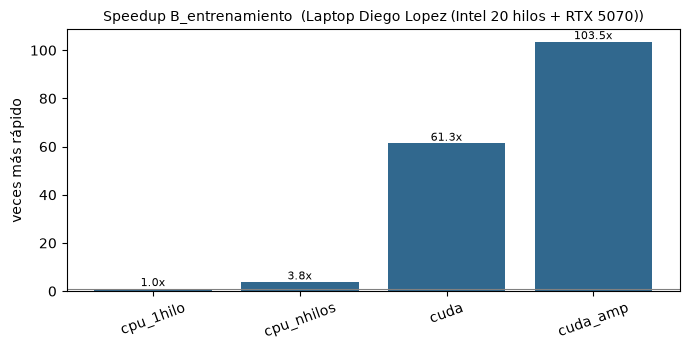

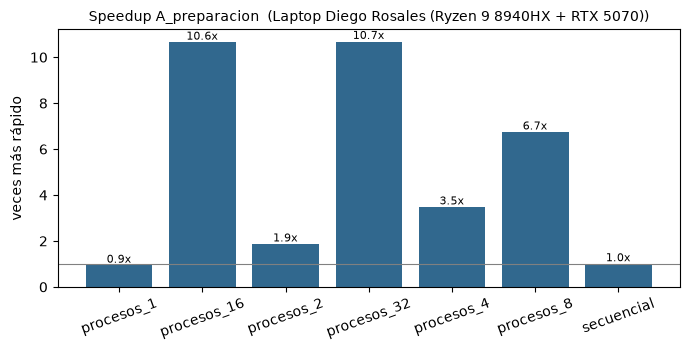

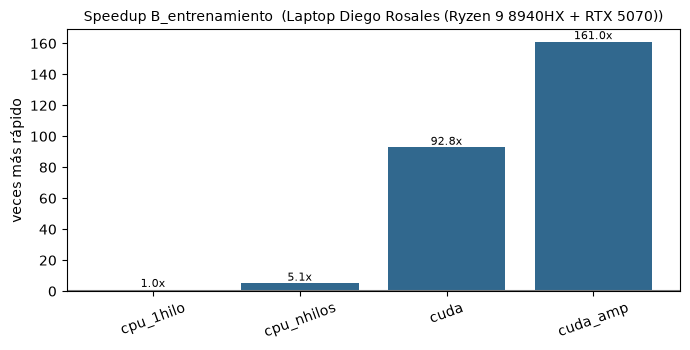

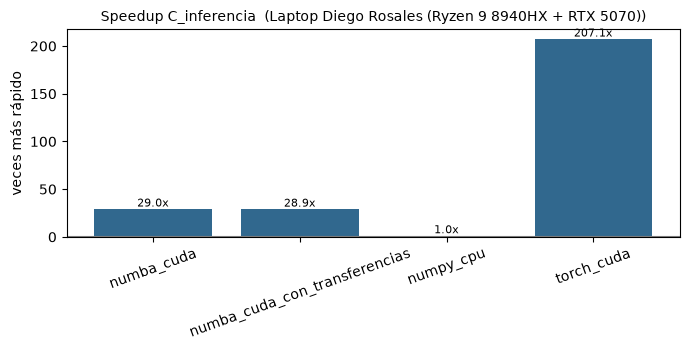

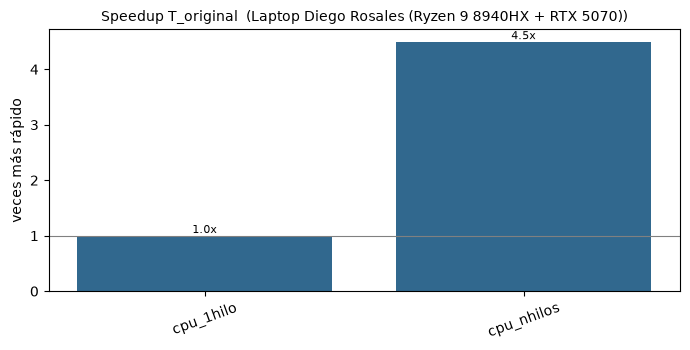

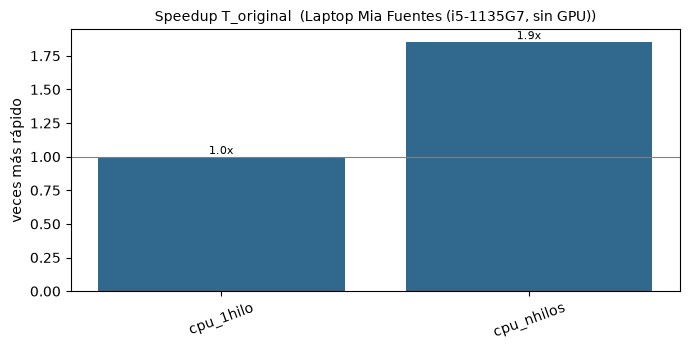

In [14]:
for (maq, fase), g in speedups.groupby(['maquina', 'fase']):
    if len(g) < 2:
        continue
    fig, ax = plt.subplots(figsize=(7, 3.6))
    barras = ax.bar(g['variante'], g['speedup'], color='#31688e')
    ax.bar_label(barras, labels=[f'{v:.1f}x' for v in g['speedup']], fontsize=8)
    ax.axhline(1, color='gray', lw=0.8)
    ax.set_ylabel('veces más rápido')
    ax.set_title(f'Speedup {fase}  ({maq})', fontsize=10)
    ax.tick_params(axis='x', labelrotation=20)
    fig.tight_layout()
    nombre = 'rosales' if 'Rosales' in maq else ('mia' if 'Mia' in maq else 'lopez')
    fig.savefig(f'resultados/figuras/speedup_{fase}_{nombre}.png', dpi=150)
    plt.show()

## 6. Evidencia de uso de recursos

Cada corrida se envolvió en `comun.monitor.Monitor`, que registra el % de cada núcleo y la utilización y memoria
de la GPU cada 0.5 s (o menos en corridas cortas). A continuación, figuras representativas de cada fase; las
capturas de pantalla de `nvidia-smi` y del Administrador de tareas están en `resultados/capturas/`.

**Preparación secuencial: 1 núcleo trabajando** (`resultados/figuras/monitor_rosales_prep_secuencial_corrida1.png`)

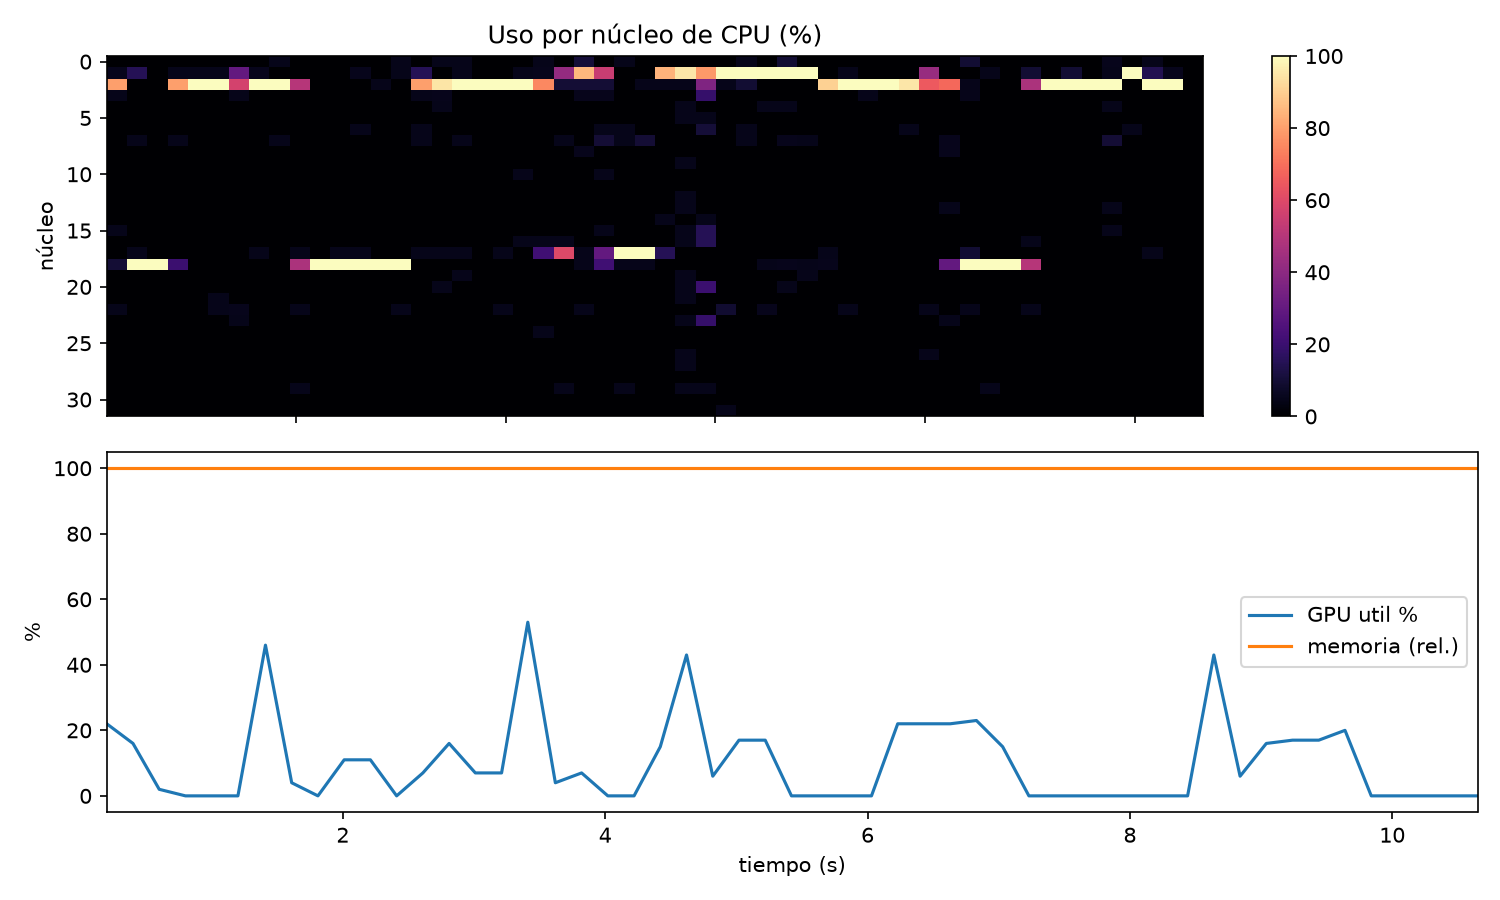

**Preparación con 16 procesos: todos los núcleos** (`resultados/figuras/monitor_rosales_prep_procesos_16_corrida1.png`)

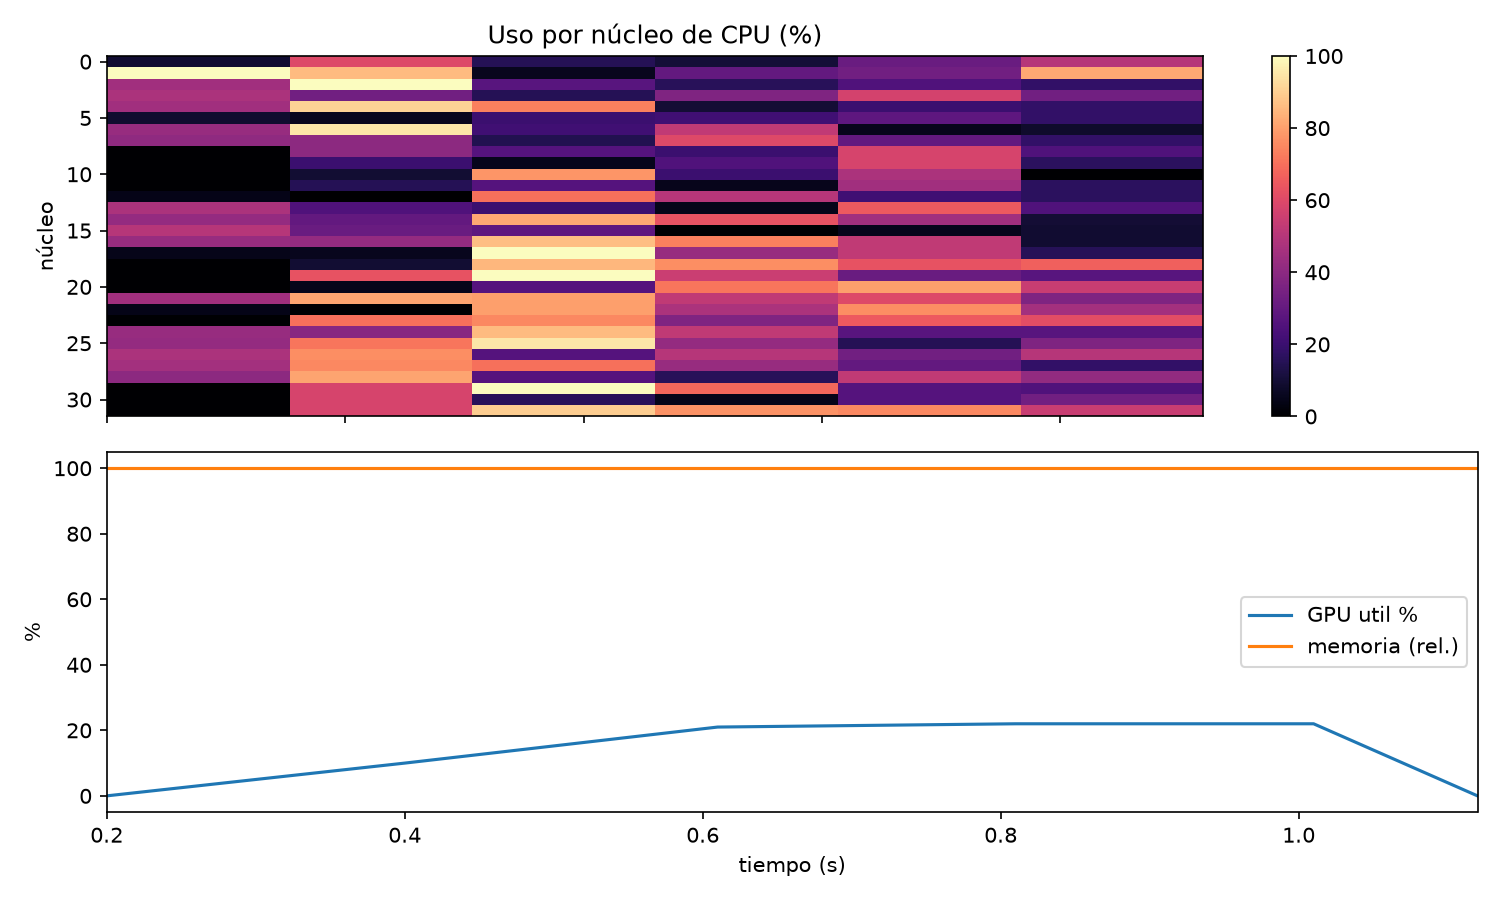

**Speedup de la preparación vs Amdahl** (`resultados/figuras/rosales_preparacion_speedup.png`)

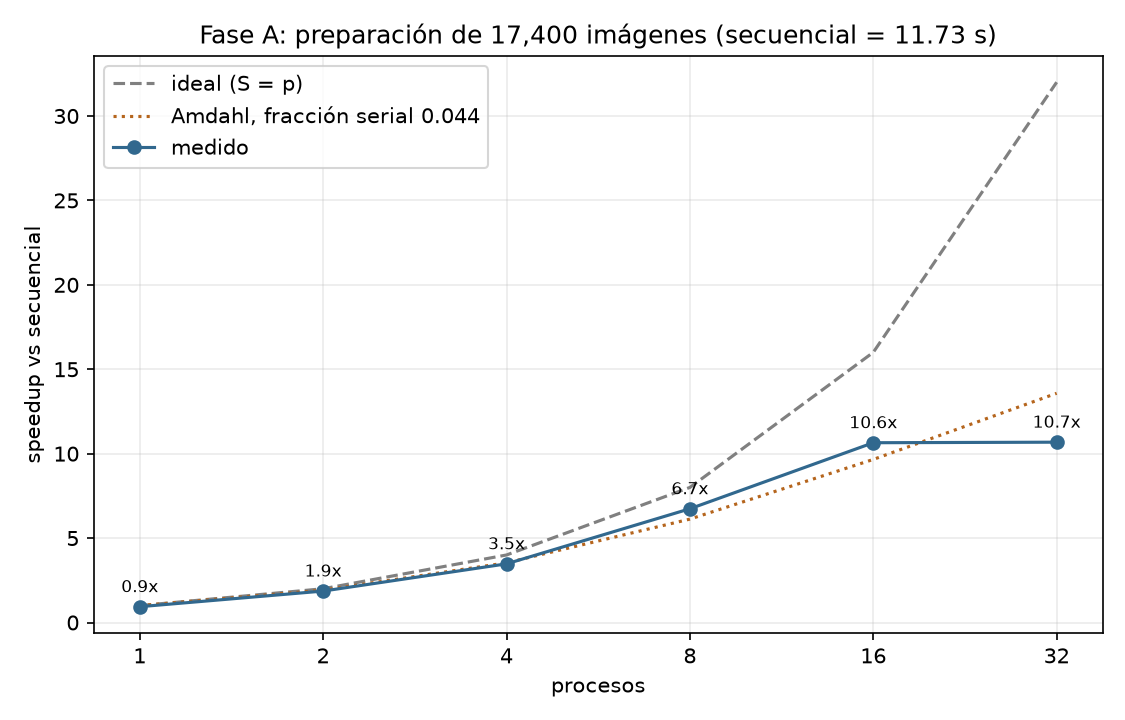

**Entrenamiento en GPU: GPU al 99 %, CPU casi libre** (`resultados/figuras/monitor_lopez_cuda_corrida1.png`)

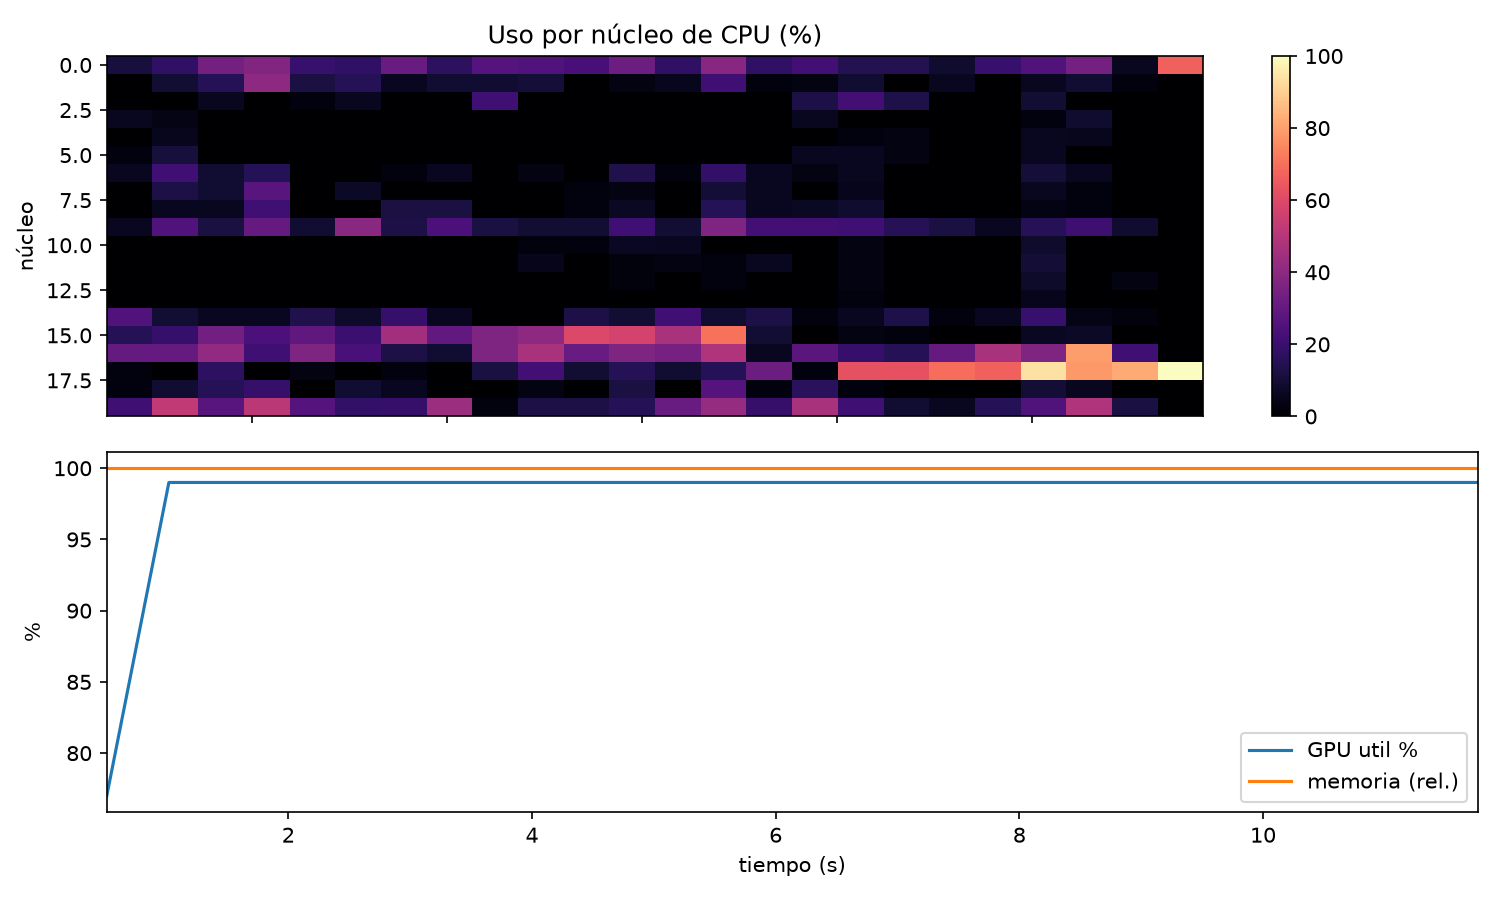

**Entrenamiento en CPU con todos los hilos** (`resultados/figuras/monitor_lopez_cpu_nhilos_corrida1.png`)

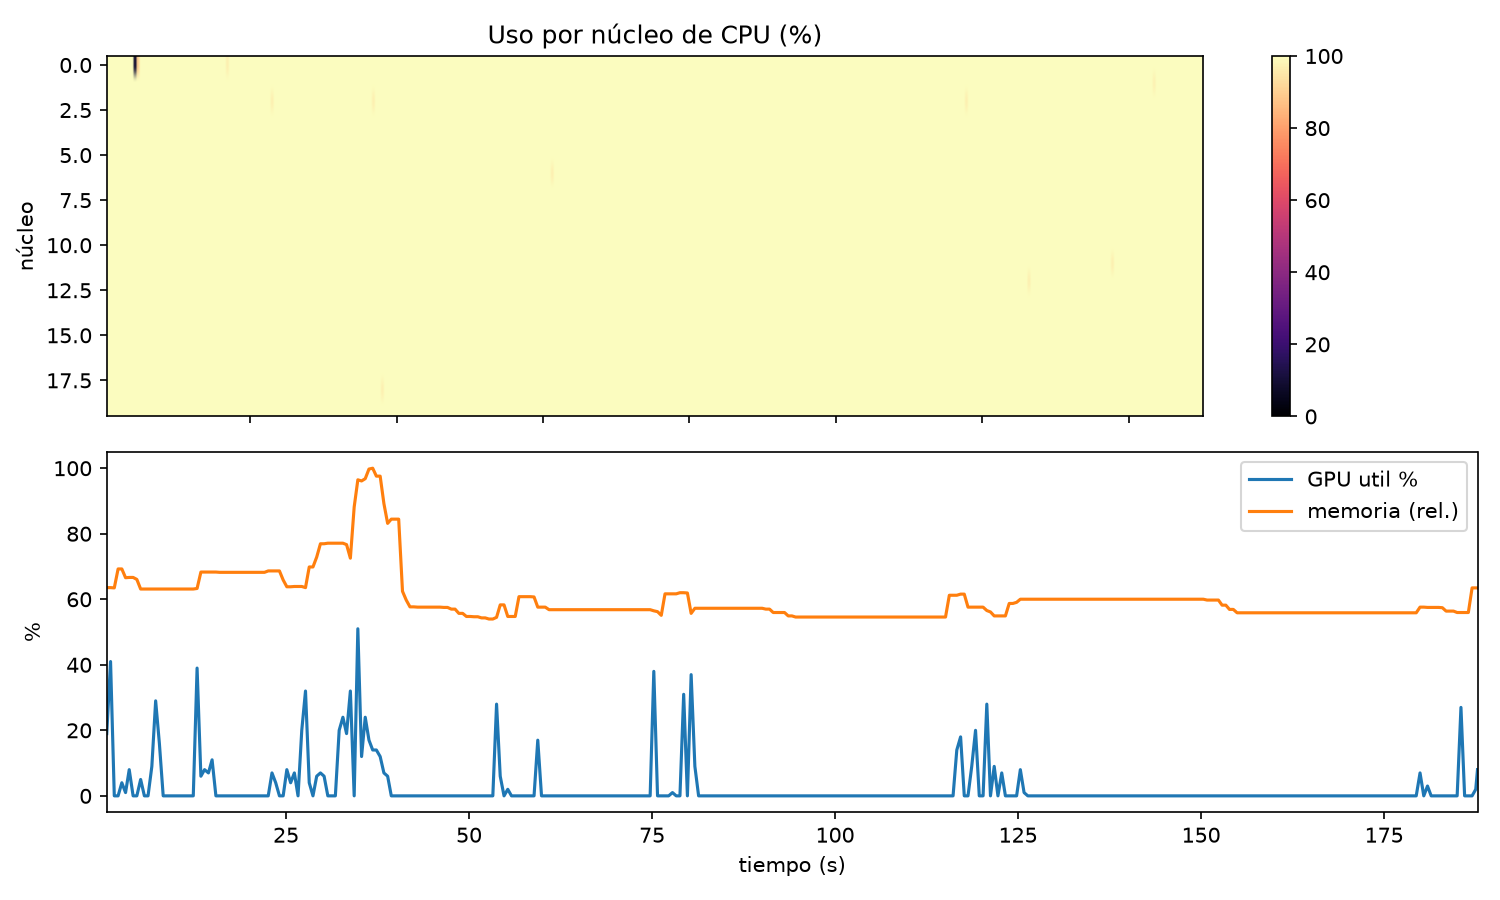

**nvidia-smi dmon durante el entrenamiento** (`resultados/figuras/lopez_dmon_gpu.png`)

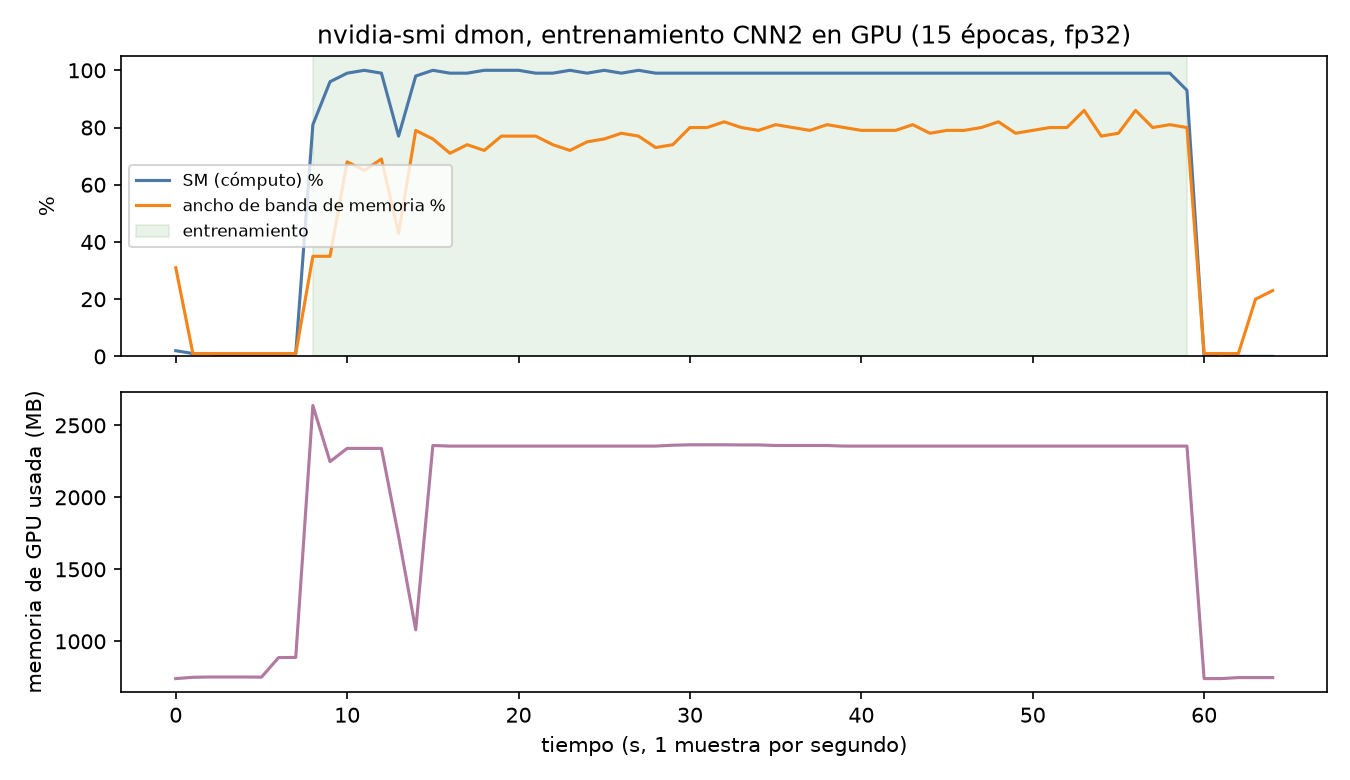

**Kernels propios: tiempo por kernel** (`resultados/figuras/rosales_kernels_desglose.png`)

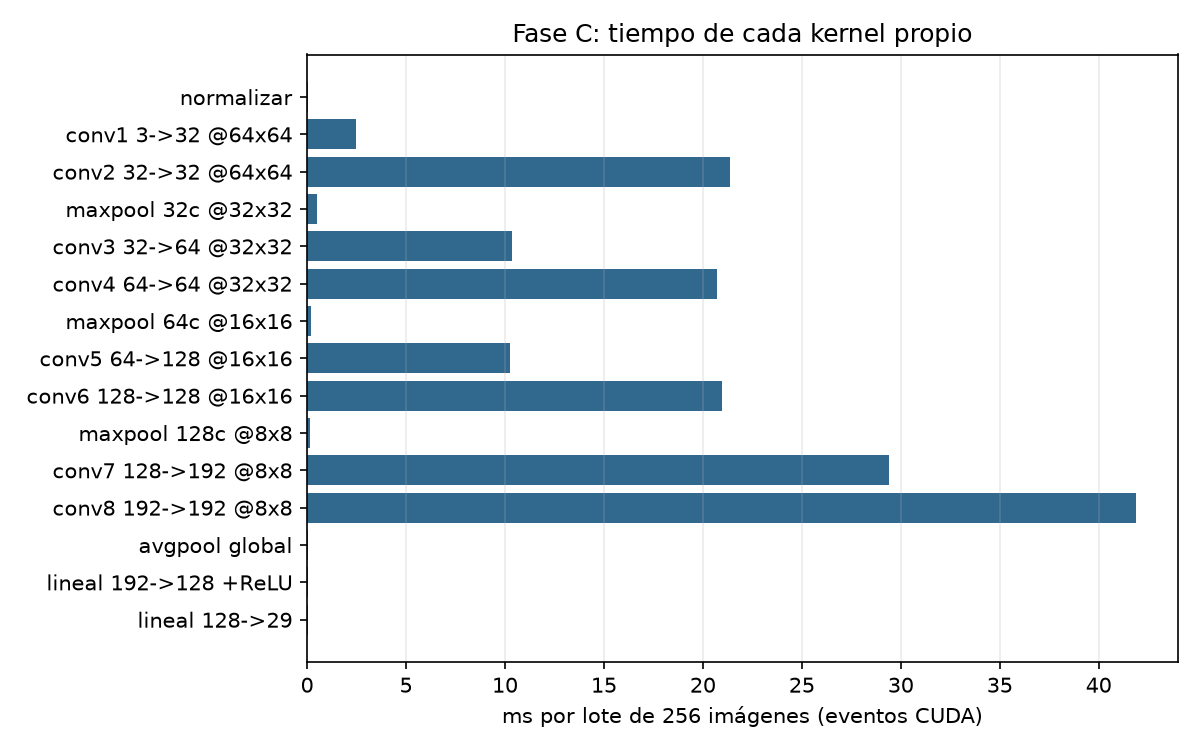

**Fase C: tiempos de inferencia** (`resultados/figuras/rosales_kernels_tiempos.png`)

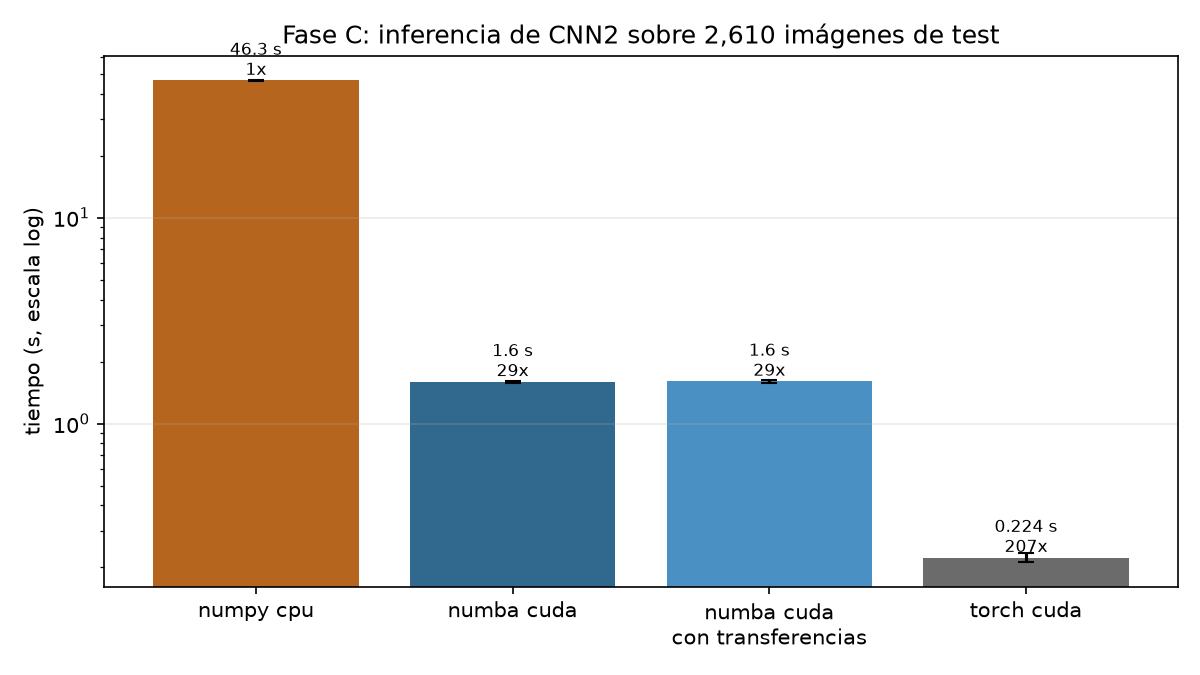

In [15]:
figuras = [
    ('Preparación secuencial: 1 núcleo trabajando', 'resultados/figuras/monitor_rosales_prep_secuencial_corrida1.png'),
    ('Preparación con 16 procesos: todos los núcleos', 'resultados/figuras/monitor_rosales_prep_procesos_16_corrida1.png'),
    ('Speedup de la preparación vs Amdahl', 'resultados/figuras/rosales_preparacion_speedup.png'),
    ('Entrenamiento en GPU: GPU al 99 %, CPU casi libre', 'resultados/figuras/monitor_lopez_cuda_corrida1.png'),
    ('Entrenamiento en CPU con todos los hilos', 'resultados/figuras/monitor_lopez_cpu_nhilos_corrida1.png'),
    ('nvidia-smi dmon durante el entrenamiento', 'resultados/figuras/lopez_dmon_gpu.png'),
    ('Kernels propios: tiempo por kernel', 'resultados/figuras/rosales_kernels_desglose.png'),
    ('Fase C: tiempos de inferencia', 'resultados/figuras/rosales_kernels_tiempos.png'),
]
for titulo, ruta in figuras:
    if os.path.exists(ruta):
        display(Markdown(f'**{titulo}** (`{ruta}`)'))
        display(Image(filename=ruta, width=760))

## 7. Discusión técnica

In [16]:
for archivo in ['fase_c_kernels_numba/discusion_p1.md', 'fase_b_entrenamiento_gpu/discusion_p2.md', 'analisis/discusion_p3.md']:
    display(Markdown(open(archivo, encoding='utf-8').read()))

# Discusión técnica, pregunta 1

## ¿Por qué es más eficiente procesar las imágenes con los múltiples núcleos del CPU y delegar exclusivamente la matemática de la red neuronal al GPU?

Porque las dos fases tienen formas de trabajo opuestas, y cada procesador está construido para una de ellas.

### La preparación de imágenes es trabajo de CPU

Preparar una imagen significa leer un archivo del disco, decodificar un JPEG, convertirlo a RGB y
redimensionarlo. Ese trabajo tiene tres características que favorecen al CPU:

1. **Es entrada/salida y llamadas al sistema.** Abrir 17,400 archivos pasa por el sistema operativo y
   el sistema de archivos. Una GPU no puede leer el disco: los bytes tienen que pasar primero por la CPU.
2. **La decodificación JPEG es irregular.** La decodificación entrópica (Huffman) es secuencial dentro de
   cada imagen y tiene muchas ramas que dependen de los datos. En una GPU eso produce divergencia de
   warps. En un núcleo de CPU, con su predicción de saltos y su caché grande, es eficiente.
3. **Las imágenes son independientes entre sí.** Ese es el paralelismo correcto para el CPU: una imagen
   completa por proceso, sin comunicación entre ellos. No hace falta paralelizar dentro de la imagen.

La fase A lo confirma. Con un pool de procesos la preparación de las 17,400 imágenes bajó de 11.7 s a
1.10 s (**10.6×** con 16 procesos) y el resultado es idéntico bit a bit al secuencial. La curva sigue
casi la recta ideal hasta 8 procesos (eficiencia del 84 %) y se aplana en 16. Con 32 no mejora, porque
el Ryzen 9 8940HX tiene 16 núcleos físicos: los 16 hilos SMT extra comparten las mismas unidades de
cálculo. La fracción serial estimada con Karp-Flatt es de entre 3 % y 6 % (crear los procesos y juntar
los resultados), y con ella Amdahl predice bien el aplanamiento.

Llevar esta fase a la GPU no tendría sentido en este proyecto. Cada imagen de 200 × 200 es un trabajo
muy pequeño, y la latencia de lanzar kernels y copiar por PCIe sería comparable al trabajo mismo.
Existen decodificadores JPEG en GPU (nvJPEG, DALI), pero rinden en flujos de video o imágenes grandes,
no en un conjunto que se prepara **una sola vez** y queda en memoria.

### La matemática de la red es trabajo de GPU

La red hace lo contrario: unos 380 millones de FLOPs por imagen (paso 1), casi todos en convoluciones
que repiten la misma multiplicación y suma sobre millones de píxeles, canales e imágenes, sin ramas que
dependan de los datos. Es exactamente para lo que existe una GPU: miles de hilos ejecutando la misma
instrucción (SIMT), memoria de alto ancho de banda y, en arquitecturas recientes, Tensor Cores.

Las mediciones lo confirman:

* **Fase B (entrenamiento, Lopez):** con los datos ya en memoria, 4 épocas de CNN2 tardan 724 s en un hilo
  de CPU, 193 s con 20 hilos y **11.8 s** en la GPU (61× contra un hilo, 16× contra todos los hilos del
  CPU). Con precisión mixta bf16 bajan a 7.0 s. La GPU se mantuvo al 99 % de uso.
* **Fase C (kernels propios):** incluso con kernels escritos a mano, sin las optimizaciones de cuDNN, la
  inferencia de las 2,610 imágenes de test bajó de 46.3 s (NumPy con 32 hilos de BLAS) a **1.60 s** (29×).

### Por qué separarlas, y no hacer todo en un solo lugar

El pipeline original mezclaba las dos fases: el `DataLoader` con `num_workers=0` volvía a abrir y
decodificar cada JPG en **cada época**, dentro del mismo bucle de entrenamiento (59,160 decodificaciones
en 4 épocas). Si ese bucle corre en la GPU, la GPU pasa la mayor parte del tiempo esperando a que un
solo núcleo de CPU termine de decodificar el siguiente lote.

Separar las fases resuelve los dos problemas a la vez:

* La CPU hace **una sola vez** el trabajo irregular, con todos sus núcleos, y deja una caché `uint8` en memoria.
* La GPU recibe lotes ya listos. La copia por PCIe es mínima (0.044 s de 11.8 s en la fase B, porque los
  datos viajan como `uint8`, 4 veces menos bytes que `float32`), y pesos, activaciones y gradientes nunca
  salen de la GPU.

Cada procesador hace lo que mejor sabe hacer, y ninguno espera al otro.


# Discusión técnica, pregunta 2: ¿cómo CUDA permitió reducir o cambiar el tiempo?

Diego Lopez, fase B (paso 5). Todo lo de abajo sale de `resultados/tiempos_lopez.csv`,
`resultados/lopez_metricas.csv`, `resultados/lopez_barrido_batch.csv` y los logs de `resultados/logs/`.

## Condiciones de la medición

| | |
|---|---|
| Hardware | Intel (20 hilos lógicos), NVIDIA GeForce RTX 5070 Laptop 8 GB, driver 596.49, Windows 11 |
| Software | Python 3.12, PyTorch 2.14.1+cu130 (CUDA 13.0, cuDNN 9.24) |
| Carga | CNN2, 4 épocas fijas, batch 256, lr 1e-3, semilla 3084, 12,180 imágenes de train + 2,610 de validación por época |
| Método | 1 corrida de calentamiento (descartada) + 5 medidas por variante; mismo bucle y misma caché en memoria en las cuatro variantes, solo cambian dispositivo, hilos y AMP |

La caché en memoria significa que **no se abre ningún JPG dentro del bucle**: este speedup mide solo la matemática de la red.
La preparación de imágenes es la fase A (otra persona) y el pipeline original con JPG en cada época es `T_original` (Mia, otra máquina); no se mezclan.

## Resultado

| Variante | Media (s) | Desv. (s) | CV | Speedup vs `cpu_1hilo` | Speedup vs `cpu_nhilos` |
|---|---:|---:|---:|---:|---:|
| `cpu_1hilo` | 723.78 | 5.21 | 0.7 % | 1.0x | n/a |
| `cpu_nhilos` (20 hilos) | 192.84 | 18.03 | 9.3 % | 3.8x | 1.0x |
| `cuda` (fp32) | 11.80 | 0.05 | 0.4 % | **61.3x** | **16.3x** |
| `cuda_amp` (bf16) | 6.99 | 0.01 | 0.1 % | **103.5x** | **27.6x** |

`cuda_amp` es 1.69x más rápida que `cuda` fp32.

Dos lecturas del speedup, y conviene reportar las dos: 61x es contra un solo hilo, la base fijada en el plan;
**16x contra la CPU usando todos sus hilos es la comparación más honesta** de "qué ganó la GPU".

## Por qué CUDA cambió el tiempo

**1. El trabajo es el que la GPU sabe hacer.** Las convoluciones y las capas lineales son miles de multiplicaciones-sumas
idénticas sobre datos independientes (cada píxel de salida, cada imagen del lote). Una CPU las reparte en 20 hilos; la GPU
las reparte en miles de hilos CUDA a la vez.

**2. El cuello de botella cambió de lugar.** En GPU, el 99.6 % del tiempo es cómputo y la transferencia es casi nula:

| | `cuda` | `cuda_amp` |
|---|---:|---:|
| Transferencia H2D (eventos CUDA) | 0.044 s | 0.041 s |
| Cómputo (forward + backward + step, eventos CUDA) | 11.749 s | 6.942 s |

Las copias cuestan ~0.4 % del tiempo. Las dos decisiones de diseño que lo explican son que los lotes viajan como `uint8`
(el `/255` se hace ya en la GPU) y que se copian desde memoria *pinned* con `non_blocking=True`, solapadas con el
cómputo del lote anterior. Con las cifras medidas: unos 0.73 GB por entrenamiento en 0.044 s, del orden de 16 GB/s
(cálculo mío a partir de los tamaños de los tensores). No medí la alternativa en `float32` sin pinned, así que el efecto
exacto de cada decisión por separado **no está medido**.

**3. La GPU quedó saturada y la CPU casi libre.** `nvidia-smi dmon` durante un entrenamiento de 15 épocas dio `sm` medio
de 98.2 % (52 muestras de 1 s) y el volcado de `nvidia-smi` mostró 99 % de utilización con 2,356 MiB.
Sumando el % de los 20 núcleos lógicos en los logs del monitor (`resultados/lopez_uso_recursos.csv`,
`resultados/figuras/lopez_uso_cpu_gpu.png`), promedio de las 5 corridas:

| Variante | Núcleos equivalentes ocupados (de 20) | Util. GPU media |
|---|---:|---:|
| `cpu_1hilo` | 1.79 | 8.7 % |
| `cpu_nhilos` | 19.99 | 1.0 % |
| `cuda` | 1.91 | 98.8 % |
| `cuda_amp` | 1.88 | 98.9 % |

Con `cuda` la CPU equivale a unos 2 núcleos ocupados mientras la GPU trabaja al ~99 %: es el pipeline pedido, la CPU
junta y reparte datos y la GPU hace la matemática. Dos aclaraciones sobre los heatmaps (`monitor_lopez_*.png`):
en `cpu_nhilos` los 20 núcleos están al ~100 % toda la corrida, pero en `cpu_1hilo` **no** se ve "un núcleo al 100 %":
Windows va moviendo el único hilo entre núcleos, por eso la carga aparece repartida en varias bandas a niveles medios
(el 1.79 incluye además ruido de fondo del sistema). La utilización de GPU de 8.7 % en `cpu_1hilo` es del escritorio y
otras aplicaciones, no del entrenamiento.

**4. AMP agrega 1.69x.** Con `autocast` bf16 las convoluciones y matmuls usan Tensor Cores y mueven la mitad de bytes.
El costo está en la sección de abajo.

## Lo que no salió como se esperaba (y no se debe esconder)

**El barrido de batch contradice la intuición "más lote, más ocupación, más rápido".**

| Batch | s por época | Util. GPU media | Memoria máx. | Test acc (media de 5) |
|---:|---:|---:|---:|---:|
| 64 | 2.72 | 96.6 % | 1,135 MiB | 0.941 |
| 128 | 2.91 | 98.8 % | 1,381 MiB | 0.895 |
| 256 | 3.06 | 98.7 % | 2,393 MiB | 0.887 |
| 512 | 3.10 | 99.8 % | 3,826 MiB | 0.764 |

La GPU ya está casi al 97 % con batch 64, así que no había ocupación que ganar: CNN2 sobre 64x64 es cómputo puro y los
lanzamientos de kernels no dominan. El tiempo incluso sube un poco con el batch. Con lr fija, el batch grande hace menos
pasos de optimización en 4 épocas, y por eso el accuracy cae (0.764 con batch 512). Una limitación del barrido: los
tamaños corrieron en orden creciente en una laptop, y no descarto que la temperatura contribuya a la subida del tiempo;
no lo medí.

**AMP no es gratis en precisión.** Con la semilla fija el resultado de `cuda_amp` es determinista (0.8333 en las 5
corridas del benchmark; 0.7897 en otro proceso: probablemente por la elección de algoritmos de cuDNN, **no verificado**).
En una prueba aparte con otras semillas, `cuda_amp` dio 0.822 a 0.900 y fp32 dio 0.889 a 0.933: en 4 épocas AMP queda
unos puntos por debajo en promedio. Son pocas muestras y con mucho ruido, así que es una tendencia, no una conclusión.
Los 103x deben citarse junto con esta salvedad.

**La CPU multihilo escala mal.** 20 hilos dan solo 3.8x sobre 1 hilo (eficiencia de ~19 %). No investigué por qué:
que las capas sean pequeñas y que haya sobrecosto de sincronización entre hilos son hipótesis, no medidas.

## Equivalencia de resultados

| Variante | Test accuracy | F1 macro |
|---|---:|---:|
| Original (Lab 3) | 0.898 | n/d |
| `cpu_1hilo` | 0.9123 | 0.9117 |
| `cpu_nhilos` | 0.8981 | 0.8961 |
| `cuda` (media de 5; mín–máx) | 0.8986 (0.862–0.924) | 0.8965 |
| `cuda_amp` | 0.8333 | 0.8264 |

`cuda` fp32 queda en el rango del original, pero la variación entre corridas (0.86 a 0.92) es grande: con 4 épocas el
modelo aún no converge. Con 15 épocas, una sola corrida en GPU llegó a **0.9981** de accuracy en test
(`resultados/logs/lopez_entrenamiento_cuda_evidencia.txt`). Las CPU dan resultados distintos entre sí con la misma
semilla (0.9123 vs 0.8981); la causa probable es que otro número de hilos cambia el orden de las sumas en coma flotante,
pero no lo verifiqué. "Mismo resultado" aquí significa "mismo rango de accuracy", no bit a bit.

## Notas de procedimiento

- **Una corrida de `cpu_1hilo` se descartó:** la laptop se suspendió ~50 min durante ella y el cronómetro contó ese tiempo
  (el log del monitor mostraba un salto de 3,009 s). Se repitió la variante completa con bloqueo de suspensión y se
  verificó que ningún log de las 5 corridas finales tenga saltos mayores a 0.53 s.
- **`cpu_nhilos` tiene CV de 9.3 %** por la corrida 5 (224.6 s contra 181–188 s en las otras cuatro), que coincidió con
  un periodo de poca memoria libre en el equipo. Se conservó en la tabla. Sin ella la media sería 184.9 s y los speedups
  de GPU contra `cpu_nhilos` serían 15.7x (fp32) y 26.5x (AMP).
- Todas las medidas son de **una sola máquina** (laptop); los speedups no se comparan con los de otros equipos.
- Evidencia de ejecución (todo sale de datos reales medidos durante el entrenamiento):
  `resultados/logs/lopez_dmon.txt` y `resultados/figuras/lopez_dmon_gpu.png` (`nvidia-smi dmon`, 1 muestra por segundo),
  `resultados/capturas/lopez_nvidia_smi_entrenando.txt` y `.png`, `resultados/figuras/monitor_lopez_*.png`,
  `resultados/figuras/lopez_uso_cpu_gpu.png` y `resultados/figuras/lopez_barrido_batch.png`.
  **Captura de pantalla real:** `resultados/capturas/lopez_taskmgr_gpu_entrenando.png` (Administrador de tareas,
  2026-11-17 00:06:44, durante un entrenamiento `cuda` de 20 épocas que duró 66.2 s y llegó a 0.9981 de accuracy en test,
  log en `resultados/logs/lopez_entrenamiento_captura.txt`): GPU NVIDIA al 100 %, 3.2 de 8.0 GB de memoria dedicada y CPU
  al 7 %. Esa memoria (3.2 GB) es la de todo el sistema, así que no es comparable con los 2,356 MiB de `nvidia-smi` de otro
  entrenamiento. La temperatura de la GPU marcó 80 °C en un entrenamiento sostenido de ~66 s (62 °C en el volcado de
  `nvidia-smi` de la corrida anterior); no medí si hubo reducción de frecuencia por temperatura.
  `lopez_nvidia_smi_entrenando.png` es la salida real de `nvidia-smi` renderizada como imagen (sin la tabla de procesos),
  **no una captura de pantalla**. Las gráficas se generaron desde los logs del monitor.


# Discusión técnica, pregunta 3

## ¿Qué factores justifican o limitan la utilización de CUDA?

CUDA se justifica cuando una parte importante del programa realiza muchas operaciones numéricas similares sobre datos independientes. Una GPU contiene numerosos núcleos capaces de ejecutar miles de hilos y ofrece gran ancho de banda de memoria. Las convoluciones, activaciones, reducciones y multiplicaciones de matrices de una red neuronal cumplen ese patrón: un mismo cálculo se aplica a muchos píxeles, canales y ejemplos. Además, librerías como cuDNN ya incluyen implementaciones optimizadas para esas operaciones.

En CNN2 la carga computacional sí es relevante. El *forward* tiene ocho convoluciones y el contador de PyTorch registra aproximadamente 379.9 millones de FLOPs por imagen para los operadores soportados. El entrenamiento añade el cálculo de gradientes y la actualización de 870,461 parámetros. Por ello, la parte matemática puede mantener ocupada una GPU, especialmente cuando se procesa un lote completo y se reutilizan pesos y activaciones sin volver a CPU.

Sin embargo, CNN2 es un modelo relativamente pequeño. Su número de parámetros y sus mapas de activación son mucho menores que los de redes modernas grandes. Si el lote fuera pequeño, habría pocos elementos disponibles simultáneamente y la GPU podría quedar subutilizada. El lote compartido de 256 ayuda a aumentar el paralelismo y amortiza costos fijos, pero también eleva la memoria necesaria para activaciones y gradientes. El tamaño máximo útil depende de la memoria disponible en la GPU; si no cabe, se debe reducir el lote, acumular gradientes o usar menor precisión.

Las transferencias CPU–GPU también limitan el beneficio. Los JPG se leen y decodifican en CPU. Copiar un lote por PCIe tiene un costo que puede dominar si el cálculo posterior es pequeño o si se transfieren datos repetidamente. La estrategia adecuada es preparar los archivos en CPU, copiar lotes suficientemente grandes y mantener en GPU las activaciones, pesos, pérdida y gradientes durante toda la iteración. Copiar cada resultado intermedio de vuelta a CPU eliminaría buena parte de la aceleración.

El lanzamiento de cada kernel CUDA tiene una sobrecarga fija. Una operación pequeña o una secuencia de muchos kernels diminutos puede tardar más en coordinación y sincronización que en cálculo. La fusión de operaciones, las librerías optimizadas y los lotes grandes ayudan a reducir ese efecto. También pueden limitar el rendimiento el ancho de banda de memoria, accesos no contiguos, divergencia de hilos, poca ocupación, sincronizaciones frecuentes y la velocidad del pipeline CPU que alimenta la GPU.

La memoria de GPU debe contener, como mínimo, parámetros, estados de Adam, gradientes y activaciones necesarias para *backward*. Aunque CNN2 cabe con holgura en una GPU moderna, no se debe asumir una capacidad concreta para todas las máquinas. Otros procesos, el contexto CUDA y el lote consumen memoria adicional. Si ocurre intercambio, falta de memoria o una reducción fuerte del lote, el rendimiento puede empeorar.

Finalmente, la ley de Amdahl indica que acelerar solo la red no acelera ilimitadamente el programa completo. Si una fracción `s` permanece serial y la fracción `1-s` se acelera `p` veces, el speedup total es `1 / (s + (1-s)/p)`. Aun con una GPU muy rápida, siguen existiendo lectura de disco, decodificación JPEG, preparación del `DataLoader`, transferencias y coordinación. Por ejemplo, si el 20 % del tiempo no se acelera, el máximo teórico al hacer infinitamente rápida la parte CUDA es 5×.

En conclusión, CUDA está justificado para la matemática densa y repetitiva de CNN2, sobre todo convoluciones y *backward*, siempre que haya lotes suficientes y que los datos permanezcan en GPU. Está limitado por el tamaño relativamente pequeño del modelo, la memoria disponible, las transferencias, el costo de lanzar kernels y las fases seriales de entrada. La decisión correcta no es trasladar todo a CUDA: la preparación de archivos corresponde a CPU multinúcleo y la red neuronal a GPU, con mediciones separadas para comprobar el beneficio real.


## 8. Conclusiones

Ver el informe PDF (`informe/`). En resumen: separar el pipeline permitió acelerar cada fase con el hardware
adecuado. La preparación de imágenes escala con los núcleos físicos del CPU, el entrenamiento en GPU es más
de un orden de magnitud más rápido que en el CPU, y la red da los mismos resultados en todas las versiones.